# Week 4 — Logistic Regression and Feature Scaling
Weeks 2–3 used logistic regression as the carrier for penalties and selection.
This week looks at logistic regression itself, and at feature scaling, across all three datasets.

**Three questions:**
- **Feature scaling:** does the way we rescale columns change the result — and is the best choice the same for every dataset?
- **RQ1 (primary):** how far ahead can failure be detected? Polish files 1 to 5 years ahead.
- **RQ4 / RQ3:** do behavioural predictors (credit card) and another market (Taiwan) behave like the Polish data?

## Datasets used

- **Polish Companies Bankruptcy** — UCI, DOI [10.24432/C5F600](https://doi.org/10.24432/C5F600).
  - **Files used:** all five, `polish_predict_1y.csv` … `polish_predict_5y.csv` (bankruptcy 1 to 5 years ahead).
    Same cleaning as Weeks 2–3: duplicates removed, 59 ratios + blank-pattern flags.
  - Each file is modelled **separately**, never mixed (no firm IDs, so the same firm may be in several files).
- **Taiwanese Bankruptcy Prediction** — UCI, DOI [10.24432/C5004D](https://doi.org/10.24432/C5004D).
  - **File used:** `taiwanese_bankruptcy.csv` — 6,819 firms, 220 bankrupt (3.2%), 94 usable ratios.
  - Cleaned this week: values outside the documented 0–1 range are treated as missing and flagged (Step 2).
- **Default of Credit Card Clients** — UCI, DOI [10.24432/C55S3H](https://doi.org/10.24432/C55S3H).
  - **File used:** `credit_card_default.csv` — 30,000 card holders, 22.1% default next month.
  - Target: `default payment next month`. Behaviour = credit limit, repayment status, bills, payments.
    Demographics = sex, education, marriage, age.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

DATA = Path("../Dataset_new/CSV")
pd.set_option("display.width", 120)
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # we record convergence ourselves instead

## Step 1 — Load the three datasets

**Polish:** the same cleaning as Weeks 2–3, wrapped in a function so all five horizons are prepared identically.

In [2]:
COPIES = ["prof_gross_interest_assets", "prof_gross_profit_assets", "act_receivables_inv_days"]
DROP   = ["liq_quick_to_lt_liab", "grow_sales_growth"]

def load_polish(h, flags=True):
    # One horizon: remove duplicate rows, drop copied / high-blank columns, add blank-pattern flags
    df = pd.read_csv(DATA / f"polish_predict_{h}y.csv")
    all64 = [c for c in df.columns if c not in ("class", "years_ahead")]
    df = df.drop_duplicates(subset=all64).reset_index(drop=True)
    cols = [c for c in all64 if c not in COPIES + DROP]
    if flags:
        blank = df[all64].isna()
        blank = blank.loc[:, blank.any()]
        for c in blank.T.drop_duplicates().index:
            df["blank_" + c] = df[c].isna().astype(int)
            cols.append("blank_" + c)
    return df[cols], df["class"]

X_pl, y_pl = load_polish(3)
print(f"Polish 3y: {X_pl.shape[1]} columns · {len(y_pl)} firms · {y_pl.mean():.2%} bankrupt")

tw = pd.read_csv(DATA / "taiwanese_bankruptcy.csv")
TW_COLS = [c for c in tw.columns if c not in ("Bankrupt?", "Net Income Flag")]   # Net Income Flag is constant
X_tw_raw, y_tw = tw[TW_COLS], tw["Bankrupt?"]
print(f"Taiwan:    {X_tw_raw.shape[1]} columns · {len(y_tw)} firms · {y_tw.mean():.2%} bankrupt")

cc = pd.read_csv(DATA / "credit_card_default.csv")
# Categories → 0/1 dummy columns, as in Week 1 (undocumented codes merged into "other")
cc["EDUCATION"] = cc["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
cc["MARRIAGE"] = cc["MARRIAGE"].replace({0: 3})
dummies = pd.get_dummies(cc[["SEX", "EDUCATION", "MARRIAGE"]].astype(str),
                         prefix=["SEX", "EDU", "MAR"], drop_first=True, dtype=int)
cc = pd.concat([cc, dummies], axis=1)
CC_COLS = (["LIMIT_BAL", "AGE"] + [c for c in cc.columns if c.startswith(("PAY_", "BILL_AMT"))]
           + list(dummies.columns))
X_cc, y_cc = cc[CC_COLS], cc["default payment next month"]
print(f"Credit:    {X_cc.shape[1]} columns · {len(y_cc)} customers · {y_cc.mean():.2%} default")

Polish 3y: 78 columns · 10416 firms · 4.73% bankrupt
Taiwan:    94 columns · 6819 firms · 3.23% bankrupt
Credit:    26 columns · 30000 customers · 22.12% default


## Step 2 — Clean the Taiwanese data

**The problem:** the Taiwanese ratios are documented as already scaled to 0–1. But 24 columns contain values in the
hundreds of thousands to billions — far outside that range.

**Check:** is there a clean gap between valid values (≤ 1) and the odd ones? If the smallest odd value is huge,
they are a different kind of number (placeholders or unscaled raw values), not extreme firms.

In [3]:
odd = pd.DataFrame({
    "rows_above_1": (X_tw_raw > 1).sum(),
    "share_above_1": (X_tw_raw > 1).mean().round(3),
    "largest_valid": X_tw_raw.where(X_tw_raw <= 1).max().round(3),
    "smallest_above_1": X_tw_raw.where(X_tw_raw > 1).min(),
})
odd = odd[odd["rows_above_1"] > 0].sort_values("rows_above_1", ascending=False)
print(len(odd), "columns have values above 1")
odd

24 columns have values above 1


,rows_above_1,share_above_1,largest_valid,smallest_above_1
Total Asset Growth Rate,6017,0.882,1.0,5.830000e+05
Cash Turnover Rate,4239,0.622,1.0,6.610000e+05
Research and development expense rate,4033,0.591,1.0,1.700000e+07
Inventory Turnover Rate (times),2946,0.432,1.0,1.910000e+07
Quick Asset Turnover Rate,2383,0.349,1.0,8.820000e+06
Operating Expense Rate,2282,0.335,1.0,6.040000e+05
Current Asset Turnover Rate,1234,0.181,1.0,3.780000e+06
Fixed Assets Turnover Frequency,1228,0.180,1.0,1.510000e+07
Interest-bearing debt interest rate,221,0.032,1.0,1.000000e+06
Long-term Liability to Current Assets,109,0.016,1.0,1.250000e+07


**Fix — the same idea as the Polish blanks:**
- Every value above 1 becomes missing (later filled with the median).
- A yes/no flag `out_<column>` records that it was out of range, so the model can still use that fact.

In [4]:
X_tw = X_tw_raw.copy()
for c in odd.index:
    X_tw["out_" + c] = (X_tw[c] > 1).astype(int)
    X_tw.loc[X_tw[c] > 1, c] = np.nan
print(f"Taiwan cleaned: {X_tw.shape[1]} columns ({len(TW_COLS)} ratios + {len(odd)} out-of-range flags)")

Taiwan cleaned: 118 columns (94 ratios + 24 out-of-range flags)


**What we found:**
- **24 Taiwanese columns break the documented 0–1 range.** The smallest odd value is 583,000; valid values stop at
  1.0 — a clean gap, so these are not extreme firms but a different kind of number (placeholders or unscaled values).
- **Most are rare** (1–221 rows), but in four columns most values are out of range: Total Asset Growth Rate 88%,
  Cash Turnover 62%, R&D expense 59%, Inventory Turnover 43%.
- **The proposal's description ("largely pre-normalised", no missing values) was wrong** — the same lesson as the
  Module B marketing data: check the values, not the labels.

## Step 3 — Logistic regression: how it works

- It computes a **score** = intercept + coefficient × column + coefficient × column + …
- It turns the score into a **probability** between 0 and 1: probability = 1 ÷ (1 + e^(−score)).
- **Coefficient → odds ratio:** e^coefficient. An odds ratio of 2 means the odds of default **double** when that
  column goes up by one unit; 0.5 means they halve; 1 means no effect.
- scikit-learn's default adds a **mild ridge penalty** (C = 1). We keep the default this week.

**Setup used everywhere this week:** fill blanks with the median → scale → logistic regression, scored by PR-AUC
with 5-fold cross-validation. Nothing is tuned, so no separate test set is needed.

In [5]:
def scaler(kind):
    if kind == "none":
        return FunctionTransformer()   # passes the data through unchanged
    if kind == "standard":
        return StandardScaler()        # z-score: (value − mean) ÷ standard deviation
    return QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0)   # ranks → bell curve

def model(kind):
    return make_pipeline(SimpleImputer(strategy="median"), scaler(kind), LogisticRegression(max_iter=5000))

def evaluate(X, y, kind, cv):
    r = cross_validate(model(kind), X, y, cv=cv, scoring="average_precision",
                       return_train_score=True, return_estimator=True, n_jobs=-1)
    base = y.mean()
    val = r["test_score"]
    return {"train_PR_AUC": r["train_score"].mean(), "val_PR_AUC": val.mean(), "val_sd": val.std(),
            "lift": val.mean() / base,
            "normalised": ((val - base) / (1 - base)).mean(),
            "converged": all(e[-1].n_iter_[0] < 5000 for e in r["estimator"])}

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

**Normalised PR-AUC** = (PR-AUC − base rate) ÷ (1 − base rate). 0 = random guessing, 1 = perfect.

Why we need it: PR-AUC starts at the base rate, and **lift can't go above 1 ÷ base rate**. The datasets (and the
five horizons) have different base rates, so raw PR-AUC and lift are not comparable between them.
Normalised PR-AUC puts every dataset on the same 0-to-1 scale.

## Step 4 — Feature scaling: does it matter, and is one method always best?

Three versions of the same model on each dataset:
- **none** — raw values;
- **standard** — z-score (mean 0, standard deviation 1);
- **quantile** — ranks mapped onto a bell curve (Week 2).

**Why scaling can matter even for one model:** the penalty treats every coefficient the same, so columns on large
scales are effectively penalised less; and the solver can fail to finish when columns differ by billions.

In [6]:
datasets = {"Polish 3y": (X_pl, y_pl), "Taiwan (raw)": (X_tw_raw, y_tw),
            "Taiwan (cleaned)": (X_tw, y_tw), "Credit card": (X_cc, y_cc)}
rows = []
for name, (X, y) in datasets.items():
    for kind in ["none", "standard", "quantile"]:
        rows.append({"dataset": name, "scaling": kind, **evaluate(X, y, kind, cv5)})
scaling_table = pd.DataFrame(rows)
scaling_table.round(3)

,dataset,scaling,train_PR_AUC,val_PR_AUC,val_sd,lift,normalised,converged
0,Polish 3y,none,0.077,0.069,0.009,1.467,0.023,False
1,Polish 3y,standard,0.315,0.263,0.025,5.567,0.227,True
2,Polish 3y,quantile,0.482,0.419,0.023,8.857,0.390,True
3,Taiwan (raw),none,0.061,0.041,0.007,1.282,0.009,True
4,Taiwan (raw),standard,0.520,0.340,0.064,10.549,0.318,True
5,Taiwan (raw),quantile,0.588,0.428,0.065,13.263,0.409,True
6,Taiwan (cleaned),none,0.416,0.391,0.048,12.104,0.370,True
7,Taiwan (cleaned),standard,0.551,0.320,0.054,9.904,0.297,True
8,Taiwan (cleaned),quantile,0.634,0.446,0.065,13.823,0.427,True
9,Credit card,none,0.496,0.495,0.006,2.238,0.352,False


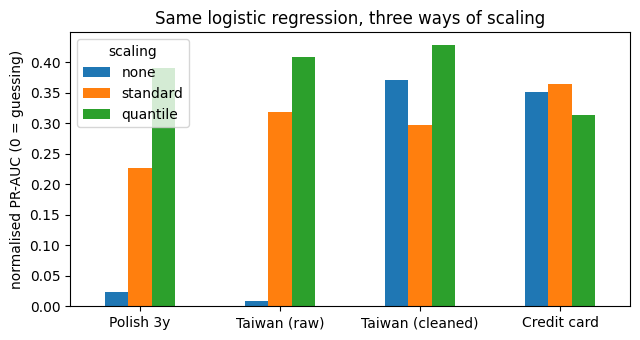

In [7]:
# Figure candidate: best scaling differs by dataset
pivot = scaling_table.pivot(index="dataset", columns="scaling", values="normalised")[["none", "standard", "quantile"]]
pivot = pivot.loc[list(datasets)]
ax = pivot.plot.bar(figsize=(6.5, 3.5), rot=0)
ax.set_ylabel("normalised PR-AUC (0 = guessing)")
ax.set_xlabel("")
ax.set_title("Same logistic regression, three ways of scaling")
plt.tight_layout()
plt.show()

**What we found:**
- **Without scaling, the bankruptcy models fail.** Polish 0.023 and raw Taiwan 0.009 are almost exactly guessing;
  the Polish solver did not even finish (`converged = False`).
- **Quantile scaling is best for bankruptcy data** — Polish 0.390, cleaned Taiwan 0.427. Financial ratios have
  extreme values, and ranking tames them.
- **Standard scaling is best for the credit card** (0.364 vs quantile 0.313). Its columns are mostly small whole
  numbers (repayment status −1, 0, 1, 2 …) with no extremes, so ranking only blurs the gaps between them.
- **So the best scaler depends on the data** — there is no single right choice.
- **Cleaning rescued Taiwan:** with no scaling, raw 0.009 → cleaned 0.370. Removing the billion-sized values made
  the data usable even unscaled.

## Step 5 — RQ1: how far ahead can failure be detected?

**What we do:** the same model (quantile scaling) on each of the five Polish horizons.

- **Repeated cross-validation:** 5 folds × 3 repeats = 15 scores per horizon, so we can see how much each one varies.
- We report **raw PR-AUC, lift and normalised PR-AUC** side by side, to show why the choice of metric matters.

In [8]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

def horizon_table(flags=True):
    rows = []
    for h in range(1, 6):
        X, y = load_polish(h, flags=flags)
        r = cross_validate(model("quantile"), X, y, cv=rcv, scoring="average_precision",
                           return_train_score=True, n_jobs=-1)
        base, val = y.mean(), r["test_score"]
        norm = (val - base) / (1 - base)
        rows.append({"years_ahead": h, "firms": len(y), "base_rate": base,
                     "train_PR_AUC": r["train_score"].mean(), "val_PR_AUC": val.mean(),
                     "lift": val.mean() / base, "max_possible_lift": 1 / base,
                     "normalised": norm.mean(), "normalised_sd": norm.std()})
    return pd.DataFrame(rows)

horizons = horizon_table()
horizons.round(3)

,years_ahead,firms,base_rate,train_PR_AUC,val_PR_AUC,lift,max_possible_lift,normalised,normalised_sd
0,1,5850,0.070,0.766,0.712,10.204,14.338,0.690,0.020
1,2,9710,0.053,0.605,0.538,10.189,18.928,0.513,0.040
2,3,10416,0.047,0.482,0.416,8.787,21.128,0.387,0.051
3,4,10083,0.039,0.502,0.419,10.624,25.334,0.395,0.058
4,5,6945,0.039,0.720,0.653,16.735,25.627,0.639,0.060


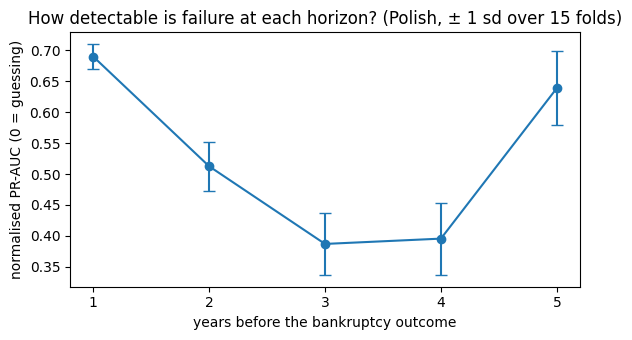

In [9]:
# Figure candidate: detectability by horizon
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(horizons["years_ahead"], horizons["normalised"], yerr=horizons["normalised_sd"],
            fmt="o-", capsize=4)
ax.set_xticks(range(1, 6))
ax.set_xlabel("years before the bankruptcy outcome")
ax.set_ylabel("normalised PR-AUC (0 = guessing)")
ax.set_title("How detectable is failure at each horizon? (Polish, ± 1 sd over 15 folds)")
plt.tight_layout()
plt.show()

**What we found:**
- **Detectability is U-shaped, not a steady decline:** 1 year 0.69 → 2 years 0.51 → 3 years 0.39 → 4 years 0.40 →
  5 years 0.64 (normalised PR-AUC).
- **Five years ahead is almost as detectable as one year ahead.** The proposal expected it to be the hardest case.
- **Lift misleads:** it ranks 5 years best (16.7× vs 10.2× for 1 year) only because its ceiling is higher
  (25.6× vs 14.3×). Normalised PR-AUC removes that effect.
- Train–validation gaps are 0.05–0.08 at every horizon, so the pattern is not caused by overfitting.

## Step 6 — Robustness: is the horizon pattern driven by the blank flags?

Week 2 showed blank patterns are strong signals. If blanks behave very differently at some horizons, they could
create the pattern on their own. **Same check without any blank flags** — ratios only.

In [10]:
horizons_no_flags = horizon_table(flags=False)
compare = pd.DataFrame({"years_ahead": horizons["years_ahead"],
                        "with_flags": horizons["normalised"],
                        "ratios_only": horizons_no_flags["normalised"]})
compare.round(3)

,years_ahead,with_flags,ratios_only
0,1,0.690,0.470
1,2,0.513,0.277
2,3,0.387,0.235
3,4,0.395,0.233
4,5,0.639,0.319


**What we found:**
- **Ratios only:** 1 year 0.47 → 2 years 0.28 → 3 years 0.24 → 4 years 0.23 → 5 years 0.32.
- **The decline from 1 to 3 years is real** — it appears in the financial ratios alone.
- **The 5-year recovery is mostly the blank flags:** 0.64 with them vs 0.32 without. Firms that will fail in five
  years seem to have distinctive gaps in their reports.
- **Blank flags help at every horizon** (e.g. 1 year 0.47 → 0.69), confirming Week 2.

## Step 7 — RQ3 / RQ4: how predictable is each dataset?

Each dataset with its **best scaling from Step 4**, scored with the same repeated cross-validation, on the same
normalised scale.

In [11]:
best = scaling_table.loc[scaling_table.groupby("dataset")["normalised"].idxmax(), ["dataset", "scaling"]]
best = dict(zip(best["dataset"], best["scaling"]))

rows = []
for name in ["Polish 3y", "Taiwan (cleaned)", "Credit card"]:
    X, y = datasets[name]
    rows.append({"dataset": name, "scaling": best[name], "base_rate": y.mean(),
                 **evaluate(X, y, best[name], rcv)})
across = pd.DataFrame(rows).drop(columns="converged")
across.round(3)

,dataset,scaling,base_rate,train_PR_AUC,val_PR_AUC,val_sd,lift,normalised
0,Polish 3y,quantile,0.047,0.482,0.416,0.048,8.787,0.387
1,Taiwan (cleaned),quantile,0.032,0.631,0.456,0.060,14.143,0.438
2,Credit card,standard,0.221,0.506,0.505,0.011,2.284,0.365


**What we found:**
- **Taiwan 0.44 · Polish 3y 0.39 · Credit card 0.36** (normalised PR-AUC, each with its best scaler).
- **RQ3:** financial ratios predict bankruptcy about as well in Taiwan as in Poland — the approach transfers to
  another market.
- **Credit card default is the hardest to predict**, even though it has far more positives (22% default).

## Step 8 — RQ4: behaviour or demographics?

**What we do:** three logistic regressions on the credit card data (standard scaling):
- **behaviour only** — credit limit, repayment status (`PAY_0` … `PAY_6`), bills, payments;
- **demographics only** — sex, education, marriage, age;
- **both**.

In [12]:
BEHAVIOUR    = ["LIMIT_BAL"] + [c for c in CC_COLS if c.startswith(("PAY_", "BILL_AMT"))]
DEMOGRAPHICS = ["AGE"] + list(dummies.columns)   # age + sex, education, marriage dummies

rows = []
for name, cols in {"behaviour only": BEHAVIOUR, "demographics only": DEMOGRAPHICS, "both": CC_COLS}.items():
    rows.append({"columns": name, "n": len(cols), **evaluate(X_cc[cols], y_cc, "standard", cv5)})
pd.DataFrame(rows).drop(columns="converged").round(3)

,columns,n,train_PR_AUC,val_PR_AUC,val_sd,lift,normalised
0,behaviour only,19,0.505,0.504,0.007,2.279,0.363
1,demographics only,7,0.256,0.255,0.006,1.151,0.043
2,both,26,0.506,0.505,0.007,2.282,0.364


**Odds ratios.** Fit the "both" model on all customers and turn each coefficient into an odds ratio. With standard
scaling, "one unit" = one standard deviation, so each odds ratio says: **how much do the odds of default change
when this column goes up by one standard deviation?**

In [13]:
full_cc = model("standard").fit(X_cc, y_cc)
odds = pd.DataFrame({"coefficient": full_cc[-1].coef_[0],
                     "odds_ratio_per_sd": np.exp(full_cc[-1].coef_[0])}, index=CC_COLS)
odds["group"] = ["demographics" if c in DEMOGRAPHICS else "behaviour" for c in CC_COLS]
odds.sort_values("odds_ratio_per_sd", key=lambda s: abs(np.log(s)), ascending=False).head(10).round(3)

,coefficient,odds_ratio_per_sd,group
PAY_0,0.648,1.912,behaviour
BILL_AMT1,-0.394,0.675,behaviour
PAY_AMT1,-0.227,0.797,behaviour
PAY_AMT2,-0.220,0.803,behaviour
BILL_AMT2,0.147,1.158,behaviour
EDU_4,-0.144,0.866,demographics
BILL_AMT3,0.119,1.126,behaviour
PAY_2,0.098,1.103,behaviour
MAR_2,-0.094,0.911,demographics
LIMIT_BAL,-0.092,0.912,behaviour


**Reading it:** odds ratio 2.0 = odds of default double per standard deviation; 0.8 = they fall by 20%.
`PAY_0` is last month's repayment status (−1 = paid on time, 1 = one month late, 2 = two months late, …).
The six monthly bills overlap (Week 1: VIF 10–16), so their odds ratios can point in opposite directions —
read the bills as one group, not one at a time.

**What we found:**
- **Demographics add nothing:** behaviour only 0.363 · demographics only 0.043 (almost guessing) · both 0.364.
- **Last month's repayment status dominates:** `PAY_0` odds ratio 1.91 — each standard deviation of lateness
  nearly **doubles** the odds of default.
- **Paying more lowers the risk:** recent payments (`PAY_AMT1`, `PAY_AMT2`) have odds ratios of about 0.80.
- **Bills point both ways** (0.67 and 1.16) because they overlap — read them as one group.
- **RQ4:** like the bankruptcy data, the signal is in **behaviour** (how payments are made), not in who the person is.

## Expected vs unexpected

These expectations were written **before** Week 4 ran: in the capstone proposal and in earlier notebooks.

**Expected**
- Detectability "decays as the horizon lengthens from one year to five", and 5 years ahead is "the hardest case"
  (proposal) → it falls from 1 to 3 years, then rises again: 5 years (0.64) is almost as detectable as 1 year (0.69)
  → **partly right**: the decline is real in the ratios alone, but the 5-year recovery comes from blank patterns.
- The Taiwanese file is "largely pre-normalised", with no missing values (proposal) → 24 columns hold values in the
  hundreds of thousands to billions → **wrong**.
- The 5-year file has "the least data for the hardest question" (Week 1) → it does have few bankrupt firms (271),
  but it is not the hardest question → **half right**.
- Scaling is mandatory before penalty-based methods (proposal) → without it the bankruptcy models fail or do not
  finish → **confirmed**.

**Unexpected**
- The best scaler is not the same for every dataset: quantile for bankruptcy, standard for the credit card.
- Lift ranks the horizons in the wrong order — the metric itself can mislead.
- Demographics alone are almost useless for predicting credit card default (0.043).

## Conclusions

1. **Feature scaling:** decides whether the model works at all. Quantile is best for skewed financial ratios;
   standard is best for the credit card's small whole-number columns. No single scaler wins everywhere.
2. **Taiwanese cleaning:** 24 columns had out-of-range values. Setting them to missing and flagging them made the
   data usable even without scaling (0.009 → 0.370) and gave the best Taiwan score (0.427).
3. **RQ1 — horizon:** detectability falls from 1 year (0.69) to 3–4 years (0.39–0.40), then rises at 5 years (0.64).
   Without blank flags the 5-year rise mostly disappears (0.32), so it comes from missing-value patterns.
4. **Metric choice:** lift ranks 5 years best only because its ceiling is higher. Normalised PR-AUC is the fair
   comparison across horizons and datasets.
5. **RQ3 — Taiwan vs Poland:** ratios predict about equally well in both markets (0.44 vs 0.39).
6. **RQ4 — behaviour vs demographics:** behaviour carries all the signal (0.363 vs 0.043). Last month's repayment
   status nearly doubles the odds of default per standard deviation.
7. **Overfitting:** train − validation gap is about 0 for the credit card, about 0.06 for Polish and 0.19 for Taiwan —
   the dataset with the fewest bankrupt firms per column overfits most (as in Week 2).
8. **Hyperparameters:** nothing was tuned this week (default C = 1). The choice that mattered was the scaler —
   effectively a preprocessing hyperparameter, and its best value depends on the data.